# M2D2 Model Evaluation

This notebook evaluates trained M2D2 models on the test set.

**Metrics**:
- Primary: Accuracy, F1-Score, AUC-ROC
- Secondary: Precision, Recall, Confusion Matrix

## 1. Setup

In [1]:
import os
import sys
from pathlib import Path
from datetime import datetime
import json

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
)
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))

from src.data.loaders import create_dataloaders
from src.models.audio_model import W2V2_Model
from src.models.visual_model import ViT_model
from src.models.text_model import TextModel
from src.models.fusion_model import Fusion
from src.utils.load_config import load_config

c:\Users\elena\Downloads\Maxi\M2D2_Multimodal_Deception_Detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Configuration

In [2]:
CHECKPOINT_PATH = "checkpoints\DOLOS_fusion_Encoders_4_Adapter_True_type_nlp_best.pt"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 16
OUTPUT_DIR = "results/evaluation"

print(f"Device: {DEVICE}")
print(f"Checkpoint: {CHECKPOINT_PATH}")

Device: cuda
Checkpoint: checkpoints\DOLOS_fusion_Encoders_4_Adapter_True_type_nlp_best.pt


<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
C:\Users\elena\AppData\Local\Temp\ipykernel_50372\1870197984.py:1: SyntaxWarning: invalid escape sequence '\D'
  CHECKPOINT_PATH = "checkpoints\DOLOS_fusion_Encoders_4_Adapter_True_type_nlp_best.pt"


In [5]:
config = load_config("../configs/default.yaml")
print("Loaded config:")
print(f"  Dataset: {config['data']['dataset']}")
print(f"  Modalities: {config['data']['modalities']}")
print(f"  Splits: {config['data']['train_split']}/{config['data']['val_split']}/{config['data']['test_split']}")

Loaded config:
  Dataset: DOLOS
  Modalities: ['video', 'audio', 'text']
  Splits: 0.7/0.15/0.15


## 3. Load Checkpoint

In [6]:
def load_checkpoint(checkpoint_path: str, device: torch.device = None):
    """Load checkpoint and return model config and state dict."""
    if device is None:
        device = torch.device("cpu")
    
    checkpoint = torch.load(checkpoint_path, map_location=device)
    
    return {
        "epoch": checkpoint.get("epoch", -1),
        "best_acc": checkpoint.get("best_acc", 0.0),
        "model_config": checkpoint.get("config", {}),
        "model_state_dict": checkpoint.get("model_state_dict", checkpoint),
    }

In [8]:
checkpoint_data = load_checkpoint("../" + CHECKPOINT_PATH, DEVICE)
model_config = checkpoint_data["model_config"]

print(f"Checkpoint epoch: {checkpoint_data['epoch']}")
print(f"Best validation accuracy: {checkpoint_data['best_acc']:.4f}")
print(f"\nModel config: {json.dumps(model_config, indent=2)}")

Checkpoint epoch: 7
Best validation accuracy: 0.6303

Model config: {
  "model_to_train": "fusion",
  "num_encoders": 4,
  "adapter": true,
  "adapter_type": "nlp",
  "fusion_type": "concat",
  "multi": false,
  "num_frames": 16
}


## 4. Initialize Model

In [9]:
def build_model(model_config: dict, device: torch.device):
    """Build model based on configuration."""
    model_type = model_config.get("model_to_train", "fusion")
    num_encoders = model_config.get("num_encoders", 4)
    adapter = model_config.get("adapter", True)
    adapter_type = model_config.get("adapter_type", "efficient_conv")
    fusion_type = model_config.get("fusion_type", "cross2")
    multi = model_config.get("multi", False)
    num_frames = model_config.get("num_frames", 16)
    
    if model_type == "audio":
        model = W2V2_Model(num_encoders, adapter, adapter_type)
    elif model_type == "vision":
        model = ViT_model(num_encoders, adapter, adapter_type)
    elif model_type == "text":
        model = TextModel(num_encoders, adapter, adapter_type)
    else:
        model = Fusion(
            fusion_type=fusion_type,
            num_encoders=num_encoders,
            adapter=adapter,
            adapter_type=adapter_type,
            multi=multi,
            num_frames=num_frames,
        )
    
    model.to(device)
    return model, model_type

In [10]:
model, model_type = build_model(model_config, DEVICE)
model.load_state_dict(checkpoint_data["model_state_dict"])
model.eval()

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Model type: {model_type}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,} ({100*trainable_params/total_params:.2f}%)")

c:\Users\elena\Downloads\Maxi\M2D2_Multimodal_Deception_Detection\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\elena\Downloads\Maxi\M2D2_Multimodal_Deception_Detection\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ViT_B_16_Weights.IMAGENET1K_V1`. You can also use `weights=ViT_B_16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3366.69it/s]
BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.we

Model type: fusion
Total parameters: 123,920,322
Trainable parameters: 5,712,194 (4.61%)


## 5. Load Test Data

In [11]:
def load_text_transcripts(text_dir: str) -> dict:
    """Load text transcripts from directory."""
    texts = {}
    if os.path.exists(text_dir):
        for fname in os.listdir(text_dir):
            if fname.endswith(".txt"):
                clip_name = fname.replace(".txt", "")
                with open(os.path.join(text_dir, fname), "r", encoding="utf-8") as f:
                    texts[clip_name] = f.read().strip()
    return texts

In [15]:
texts_dict = None
if model_type in ["text", "fusion"]:
    texts_dict = load_text_transcripts(config["paths"]["text_dir"])
    print(f"Loaded {len(texts_dict)} text transcripts")

loader_config = {
    "batch_size": BATCH_SIZE,
    "num_frames": config["data"]["video"]["num_frames"],
    "frame_size": config["data"]["video"]["resize"][0],
    "num_audio_tokens": 64,
    "train_split": config["data"]["train_split"],
    "val_split": config["data"]["val_split"],
    "test_split": config["data"]["test_split"],
    "class_weights": config["training"]["class_weights"],
}

_, _, test_loader = create_dataloaders(
    annotations_file="../" + config["paths"]["annotations"],
    audio_dir="../" +config["paths"]["audio_dir"],
    img_dir="../" +config["paths"]["image_dir"],
    config=loader_config,
    texts=texts_dict,
    use_mock_text=False,
    num_workers=4,
)

print(f"Test set size: {len(test_loader.dataset)} samples")
print(f"Test batches: {len(test_loader)}")

2026-04-22 10:11:13 [WARNING] src.data.validation: Found 270 missing clips out of 1677 annotated
2026-04-22 10:11:13 [WARNING] src.data.validation: Missing clip: AN_WILTY_EP16_truth9
2026-04-22 10:11:13 [WARNING] src.data.validation: Missing clip: AN_WILTY_EP17_truth12
2026-04-22 10:11:13 [WARNING] src.data.validation: Missing clip: AN_WILTY_EP17_truth2
2026-04-22 10:11:13 [WARNING] src.data.validation: Missing clip: AN_WILTY_EP19_truth4
2026-04-22 10:11:13 [WARNING] src.data.validation: Missing clip: AN_WILTY_EP22_lie22
2026-04-22 10:11:13 [WARNING] src.data.validation: Missing clip: AN_WILTY_EP22_truth1
2026-04-22 10:11:13 [WARNING] src.data.validation: Missing clip: AN_WILTY_EP23_truth9
2026-04-22 10:11:13 [WARNING] src.data.validation: Missing clip: AN_WILTY_EP24_truth12
2026-04-22 10:11:13 [WARNING] src.data.validation: Missing clip: AN_WILTY_EP26_lie14
2026-04-22 10:11:13 [WARNING] src.data.validation: Missing clip: AN_WILTY_EP26_truth8
2026-04-22 10:11:13 [WARNING] src.data.vali

Loaded 0 text transcripts


2026-04-22 10:11:14 [WARNING] src.data.validation: Missing clip: SJ_WILTY_EP71_true_6
2026-04-22 10:11:14 [WARNING] src.data.validation: Missing clip: SJ_WILTY_EP71_true_7
2026-04-22 10:11:14 [WARNING] src.data.validation: Missing clip: SJ_WILTY_EP71_true_8
2026-04-22 10:11:14 [WARNING] src.data.validation: Missing clip: SJ_WILTY_EP71_true_9
2026-04-22 10:11:14 [WARNING] src.data.validation: Missing clip: YW_WILTY_EP43_truth1 
2026-04-22 10:11:14 [WARNING] src.data.validation: Missing clip: YW_WILTY_EP43_truth7
2026-04-22 10:11:14 [WARNING] src.data.validation: Missing clip: YW_WILTY_EP43_truth8
2026-04-22 10:11:14 [WARNING] src.data.validation: Missing clip: YW_WILTY_EP47_lie17
2026-04-22 10:11:14 [WARNING] src.data.validation: Missing clip: YW_WILTY_EP47_lie4
2026-04-22 10:11:14 [WARNING] src.data.validation: Missing clip: YW_WILTY_EP47_lie7
2026-04-22 10:11:14 [WARNING] src.data.validation: Missing clip: YW_WILTY_EP47_lie8
2026-04-22 10:11:14 [WARNING] src.data.validation: Missing c

Test set size: 213 samples
Test batches: 14


## 6. Run Inference

In [16]:
def run_inference(model, test_loader, model_type, device):
    """Run inference on test set and return predictions and labels."""
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []
    
    with torch.no_grad():
        for batch in test_loader:
            labels = batch["label"].to(device)
            
            if model_type == "audio":
                waves = batch["audio"].squeeze(1).to(device)
                logits = model(waves)
            elif model_type == "vision":
                faces = batch["video"].to(device)
                logits = model(faces)
            elif model_type == "text":
                input_ids = batch["text_ids"].to(device)
                attention_mask = batch["text_mask"].to(device)
                logits = model(input_ids, attention_mask)
            else:
                waves = batch["audio"].squeeze(1).to(device)
                faces = batch["video"].to(device)
                input_ids = batch["text_ids"].to(device)
                attention_mask = batch["text_mask"].to(device)
                logits, _, _, _ = model(waves, faces, input_ids, attention_mask)
            
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(logits, dim=1)
            
            all_preds.append(preds.cpu())
            all_labels.append(labels.cpu())
            all_probs.append(probs.cpu())
    
    return (
        torch.cat(all_preds).numpy(),
        torch.cat(all_labels).numpy(),
        torch.cat(all_probs).numpy(),
    )

In [17]:
print("Running inference on test set...")
predictions, labels, probabilities = run_inference(model, test_loader, model_type, DEVICE)
print(f"Completed inference on {len(labels)} samples")

Running inference on test set...
Completed inference on 213 samples


## 7. Compute Metrics

In [18]:
def compute_metrics(labels, predictions, probabilities):
    """Compute all evaluation metrics."""
    metrics = {
        "accuracy": accuracy_score(labels, predictions),
        "f1_score": f1_score(labels, predictions),
        "precision": precision_score(labels, predictions),
        "recall": recall_score(labels, predictions),
        "auc_roc": roc_auc_score(labels, probabilities[:, 1]),
    }
    return metrics

In [19]:
metrics = compute_metrics(labels, predictions, probabilities)

print("=" * 50)
print("TEST SET RESULTS")
print("=" * 50)
print(f"Accuracy:  {metrics['accuracy']:.4f}")
print(f"F1-Score:  {metrics['f1_score']:.4f}")
print(f"Precision: {metrics['precision']:.4f}")
print(f"Recall:    {metrics['recall']:.4f}")
print(f"AUC-ROC:   {metrics['auc_roc']:.4f}")
print("=" * 50)

TEST SET RESULTS
Accuracy:  0.5352
F1-Score:  0.6502
Precision: 0.5318
Recall:    0.8364
AUC-ROC:   0.5513


## 8. Classification Report

In [20]:
report = classification_report(
    labels, predictions, target_names=["Truth", "Deception"], digits=4
)
print(report)

              precision    recall  f1-score   support

       Truth     0.5500    0.2136    0.3077       103
   Deception     0.5318    0.8364    0.6502       110

    accuracy                         0.5352       213
   macro avg     0.5409    0.5250    0.4789       213
weighted avg     0.5406    0.5352    0.4846       213



## 9. Confusion Matrix

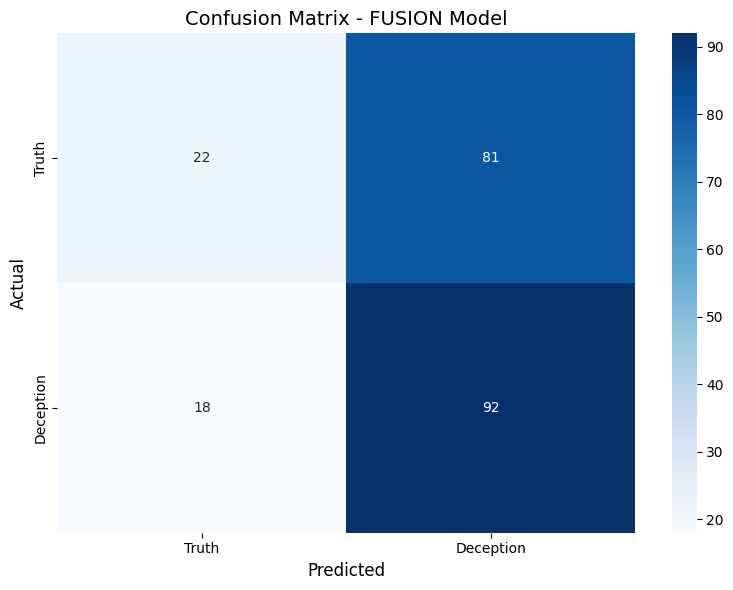


Confusion Matrix:
  True Negatives (Truth -> Truth):  22
  False Positives (Truth -> Decep): 81
  False Negatives (Decep -> Truth): 18
  True Positives (Decep -> Decep):  92


In [27]:
cm = confusion_matrix(labels, predictions)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Truth", "Deception"],
    yticklabels=["Truth", "Deception"],
    ax=ax,
)
ax.set_xlabel("Predicted", fontsize=12)
ax.set_ylabel("Actual", fontsize=12)
ax.set_title(f"Confusion Matrix - {model_type.upper()} Model", fontsize=14)
plt.tight_layout()
plt.show()

print(f"\nConfusion Matrix:")
print(f"  True Negatives (Truth -> Truth):  {cm[0, 0]}")
print(f"  False Positives (Truth -> Decep): {cm[0, 1]}")
print(f"  False Negatives (Decep -> Truth): {cm[1, 0]}")
print(f"  True Positives (Decep -> Decep):  {cm[1, 1]}")

## 10. ROC Curve

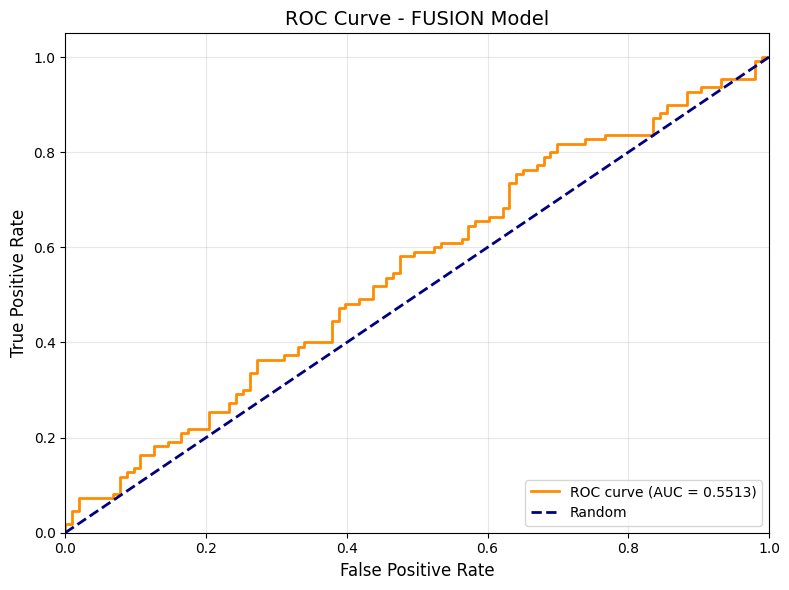

In [28]:
fpr, tpr, thresholds = roc_curve(labels, probabilities[:, 1])
auc_score = roc_auc_score(labels, probabilities[:, 1])

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_score:.4f})")
ax.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Random")
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.set_title(f"ROC Curve - {model_type.upper()} Model", fontsize=14)
ax.legend(loc="lower right", fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Save Results

In [29]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

results = {
    "checkpoint": CHECKPOINT_PATH,
    "model_type": model_type,
    "model_config": model_config,
    "test_samples": len(labels),
    "metrics": metrics,
    "confusion_matrix": cm.tolist(),
    "timestamp": datetime.now().isoformat(),
}

results_file = os.path.join(
    OUTPUT_DIR, f"evaluation_{model_type}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.json"
)

with open(results_file, "w") as f:
    json.dump(results, f, indent=2)

print(f"Results saved to: {results_file}")

Results saved to: results/evaluation\evaluation_fusion_20260422_101242.json


In [30]:
cm_file = os.path.join(
    OUTPUT_DIR, f"confusion_matrix_{model_type}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.png"
)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Truth", "Deception"],
    yticklabels=["Truth", "Deception"],
    ax=ax,
)
ax.set_xlabel("Predicted", fontsize=12)
ax.set_ylabel("Actual", fontsize=12)
ax.set_title(f"Confusion Matrix - {model_type.upper()} Model", fontsize=14)
plt.tight_layout()
plt.savefig(cm_file, dpi=150, bbox_inches="tight")
plt.close()

print(f"Confusion matrix saved to: {cm_file}")

Confusion matrix saved to: results/evaluation\confusion_matrix_fusion_20260422_101242.png


In [31]:
roc_file = os.path.join(
    OUTPUT_DIR, f"roc_curve_{model_type}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.png"
)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_score:.4f})")
ax.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Random")
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.set_title(f"ROC Curve - {model_type.upper()} Model", fontsize=14)
ax.legend(loc="lower right", fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(roc_file, dpi=150, bbox_inches="tight")
plt.close()

print(f"ROC curve saved to: {roc_file}")

ROC curve saved to: results/evaluation\roc_curve_fusion_20260422_101243.png


## 12. Summary

In [32]:
print("\n" + "=" * 60)
print("EVALUATION SUMMARY")
print("=" * 60)
print(f"Model:        {model_type.upper()}")
print(f"Checkpoint:   {CHECKPOINT_PATH}")
print(f"Test samples: {len(labels)}")
print("-" * 60)
print(f"Accuracy:     {metrics['accuracy']:.4f} ({metrics['accuracy']*100:.2f}%)")
print(f"F1-Score:     {metrics['f1_score']:.4f}")
print(f"AUC-ROC:      {metrics['auc_roc']:.4f}")
print("-" * 60)
print(f"Target range: 75-85% accuracy")
if metrics['accuracy'] >= 0.75:
    print("Status: TARGET MET")
else:
    print("Status: BELOW TARGET")
print("=" * 60)


EVALUATION SUMMARY
Model:        FUSION
Checkpoint:   checkpoints\DOLOS_fusion_Encoders_4_Adapter_True_type_nlp_best.pt
Test samples: 213
------------------------------------------------------------
Accuracy:     0.5352 (53.52%)
F1-Score:     0.6502
AUC-ROC:      0.5513
------------------------------------------------------------
Target range: 75-85% accuracy
Status: BELOW TARGET
